<xarray.Dataset> Size: 2GB
Dimensions:  (time: 1476, lat: 360, lon: 720)
Coordinates:
  * time     (time) datetime64[ns] 12kB 1901-01-16 1901-02-15 ... 2023-12-16
  * lat      (lat) float64 3kB -89.75 -89.25 -88.75 -88.25 ... 88.75 89.25 89.75
  * lon      (lon) float64 6kB -179.8 -179.2 -178.8 -178.2 ... 178.8 179.2 179.8
Data variables:
    spei     (time, lat, lon) float32 2GB ...
    crs      int32 4B ...
Attributes: (12/15)
    conventions:  CF-1.11
    title:        Global 12-months SPEI, z-values, 0.5 degree
    version:      2.10.0
    id:           ./outputNcdf/spei12.nc
    summary:      Global dataset of the Standardized Precipitation-Evapotrans...
    keywords:     drought, climatology, SPEI, Standardized Precipitation-Evap...
    ...           ...
    software:     Created in R using the SPEI package (https://cran.r-project...
    call:         spei.nc(sca=i, inPre=./inputData/cru_ts4.08.1901.2023.pre.d...
    date:         Wed Jul 10 11:04:12 2024
    reference:    Beguer

FileNotFoundError: [Errno 2] No such file or directory: 'data/raw/ca_spei_sanity_check.png'

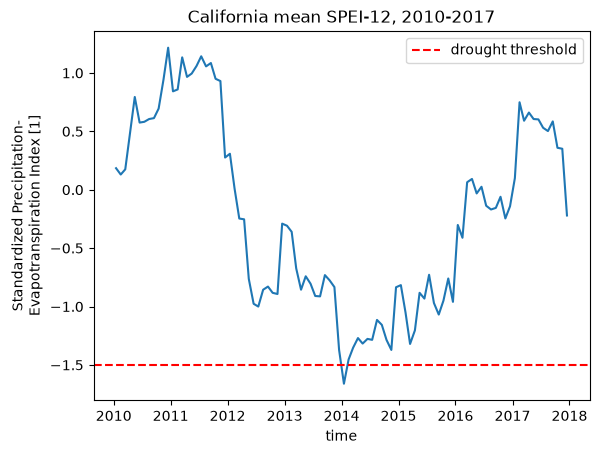

In [2]:
import xarray as xr
import matplotlib.pyplot as plt

ds = xr.open_dataset("../data/raw/spei12.nc")
print(ds)

# California bounding box (rough, 0.5 deg grid so don't over-tighten yet)
ca_bbox = dict(lat=slice(32, 42), lon=slice(-124, -114))
spei_ca = ds["spei"].sel(**ca_bbox).mean(dim=["lat", "lon"])

spei_ca.sel(time=slice("2010-01-01", "2017-12-31")).plot()
plt.axhline(-1.5, color="red", linestyle="--", label="drought threshold")
plt.title("California mean SPEI-12, 2010-2017")
plt.legend()
plt.savefig("data/raw/ca_spei_sanity_check.png")


In [3]:
import ee
ee.Authenticate()
ee.Initialize(project="tree-fire-510209")

agb = ee.ImageCollection("ESA/CCI/Above_Ground_Biomass/V6_0")
print(agb.aggregate_array("system:index").getInfo())  # confirm available years / band naming


['2007', '2010', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022']


In [4]:
import ee
ee.Initialize(project="tree-fire-510209")

sierra_bbox = ee.Geometry.Rectangle([-119.5, 35.5, -118.5, 37.5])
agb = ee.ImageCollection("ESA/CCI/Above_Ground_Biomass/V6_0")

years = ["2010", "2015", "2016", "2017", "2018"]
for yr in years:
    img = agb.filter(ee.Filter.eq("system:index", yr)).first().clip(sierra_bbox)
    url = img.getDownloadURL({
        "scale": 100,          # matches fire-impact-curves' biomass resolution; adjust if different
        "region": sierra_bbox,
        "format": "GEO_TIFF",
    })
    print(yr, url)


2010 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/c1bf8b2ef2fd11e931da2675f813b9bb-0f690884e912fd7a88b41cd7aa8ae577:getPixels
2015 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/434a51eb530c8b3bb38c64139c63090b-268651be5151a808621602a993bf79a2:getPixels
2016 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/9319355ca5b2d01cf1ec5c3147d70540-eed3e5b74ba1e093e1ca7e4ff58518a3:getPixels
2017 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/129f7e634153fb122668e28903c8e85c-d9c30725e0906b241b5ed7f9bb883d8a:getPixels
2018 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/8489a16d2966278f64de1b5cb233302f-c99c018d296a1ab3106192c1283cf708:getPixels


In [7]:
import rasterio
import numpy as np

for yr in ["2010", "2015", "2016", "2017", "2018"]:
    with rasterio.open(f"../data/raw/agb/agb_{yr}.tif") as src:
        arr = src.read(1, masked=True)
        print(yr, "dtype:", src.dtypes[0], "bands:", src.count,
              "descriptions:", src.descriptions, "shape:", arr.shape,
              "mean:", arr.mean(), "nodata:", src.nodata)

2010 dtype: uint16 bands: 2 descriptions: (None, None) shape: (2229, 1114) mean: 65.24052103976463 nodata: 0.0
2015 dtype: uint16 bands: 2 descriptions: (None, None) shape: (2229, 1114) mean: 66.63343100792368 nodata: 0.0
2016 dtype: uint16 bands: 2 descriptions: (None, None) shape: (2229, 1114) mean: 66.20392643435821 nodata: 0.0
2017 dtype: uint16 bands: 2 descriptions: (None, None) shape: (2229, 1114) mean: 66.9281939618371 nodata: 0.0
2018 dtype: uint16 bands: 2 descriptions: (None, None) shape: (2229, 1114) mean: 66.83414076645371 nodata: 0.0


In [8]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

with rasterio.open("../data/raw/agb/agb_2010.tif") as src:
    print("band descriptions:", src.descriptions)
    print("tags:", src.tags())
    for b in (1, 2):
        print("band", b, "tags:", src.tags(b))


band descriptions: (None, None)
tags: {'TIFFTAG_XRESOLUTION': '1', 'TIFFTAG_YRESOLUTION': '1', 'TIFFTAG_RESOLUTIONUNIT': '1 (unitless)', 'AREA_OR_POINT': 'Area'}
band 1 tags: {}
band 2 tags: {}


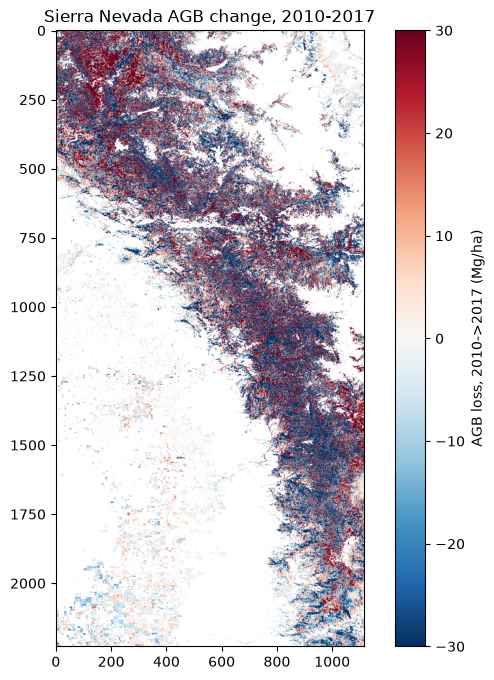

In [9]:
with rasterio.open("../data/raw/agb/agb_2010.tif") as src:
    agb_2010 = src.read(1, masked=True).astype("float32")
    agb_2010 = np.ma.filled(agb_2010, np.nan)

with rasterio.open("../data/raw/agb/agb_2017.tif") as src:
    agb_2017 = src.read(1, masked=True).astype("float32")
    agb_2017 = np.ma.filled(agb_2017, np.nan)

loss = agb_2010 - agb_2017  # positive = loss

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(loss, cmap="RdBu_r", vmin=-30, vmax=30)
plt.colorbar(im, label="AGB loss, 2010->2017 (Mg/ha)")
plt.title("Sierra Nevada AGB change, 2010-2017")
plt.savefig("../data/raw/agb_loss_map_2010_2017.png", dpi=150)
plt.show()


In [10]:
import rasterio
import numpy as np

with rasterio.open("../data/raw/agb/agb_2010.tif") as src:
    b1 = src.read(1, masked=True)
    b2 = src.read(2, masked=True)
    print("band 1: mean", b1.mean(), "std", b1.std(), "max", b1.max())
    print("band 2: mean", b2.mean(), "std", b2.std(), "max", b2.max())


band 1: mean 65.24052103976463 std 55.80579090321611 max 313
band 2: mean 40.22971690796379 std 35.29306607072867 max 233
